# Chapitre 1 - Cours 2 : décrire la performance, temps de réponse et percentiles

Comment dire qu'un service est « rapide » ? Ce notebook construit le vocabulaire et les
outils de mesure de la performance : temps de réponse, temps de service et latence ;
distributions plutôt que moyennes ; percentiles et leur calcul en continu ; effet des
appels multiples sur la queue de distribution ; objectifs et contrats de niveau de
service. Il couvre la sous-section *Describing Performance* de la section *Scalability* (et son encadré *Percentiles in Practice*).

**Plan.**

1. Débit et temps de réponse.
2. Temps de réponse, temps de service et latence, mesurés côté client et côté serveur.
3. Une distribution, pas un nombre : moyenne, médiane et percentiles.
4. Calculer des percentiles en continu : fenêtres glissantes et histogrammes.
5. L'amplification de la latence de queue.
6. Objectifs et contrats de niveau de service (SLO et SLA).

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import requirements as rq
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                           annotate_bars, finish, set_style, subtitle)
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 1)
rng = np.random.default_rng(0)
Q = [50, 90, 95, 99, 99.9]

## 1. Débit et temps de réponse (section *Describing Performance*)

Deux grandes familles de métriques décrivent la performance d'un logiciel :

- le **débit** (throughput) : nombre de requêtes, ou volume de données, traités par
  seconde. Pour un matériel donné, il existe un débit maximal ;
- le **temps de réponse** : durée entre l'envoi d'une requête par l'utilisateur et la
  réception de la réponse, en secondes ou millisecondes.

Dans l'étude de cas du cours 1, « messages publiés par seconde » et « écritures de
timeline par seconde » sont des débits ; « temps de chargement de la timeline » et
« délai avant qu'un message soit livré aux abonnés » sont des temps de réponse.
Le livre note que les systèmes de traitement par lots (comme Hadoop) se jugent surtout au débit, et les services en ligne au temps de réponse.
Les deux sont liés : le temps de réponse augmente à mesure que le débit approche de la
capacité, à cause des **files d'attente** (cours 3). Le temps de réponse est ce que
ressentent les utilisateurs ; le débit détermine les ressources nécessaires, donc le coût.

> **À retenir.** Débit (« combien par seconde ») et temps de réponse (« combien de temps
> pour une requête ») sont les deux métriques de base ; le premier fixe le coût, le
> second l'expérience utilisateur.

## 2. Temps de réponse, temps de service et latence (section *Describing Performance*)

Les mots « latence » et « temps de réponse » sont souvent employés l'un pour l'autre. Le
livre les distingue :

- le **temps de réponse** est ce que voit le client : il inclut tous les délais, où qu'ils
  se produisent ;
- le **temps de service** est la durée pendant laquelle le serveur traite activement la
  requête ;
- les **délais d'attente en file** (queueing delays) surviennent à plusieurs endroits :
  attendre qu'un cœur se libère, qu'un tampon réseau se vide ;
- la **latence** désigne le temps pendant lequel la requête n'est pas traitée, où elle est
  « latente » ; la **latence réseau** est le temps passé à voyager sur le réseau.

Le diagramme espace-temps ci-dessous (le temps s'écoule de gauche à droite, une ligne
par acteur) décompose une requête qui arrive sur un serveur occupé.

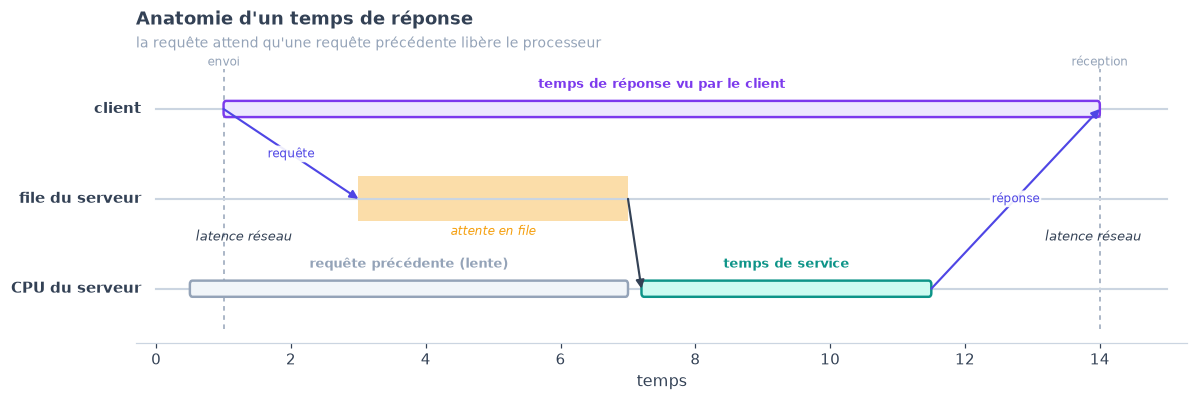

In [2]:
st = SpaceTime(["client", "file du serveur", "CPU du serveur"], t_max=15, width=11,
               title="Anatomie d'un temps de réponse",
               subtitle="la requête attend qu'une requête précédente libère le processeur")
st.op("CPU du serveur", 0.5, 7.0, "requête précédente (lente)", color=GRAY)
st.msg("client", 1.0, "file du serveur", 3.0, "requête", color=INDIGO)
st.span("file du serveur", 3.0, 7.0, "attente en file", color=AMBER, alpha=0.35)
st.msg("file du serveur", 7.0, "CPU du serveur", 7.2, "", color=SLATE)
st.op("CPU du serveur", 7.2, 11.5, "temps de service", color=TEAL)
st.msg("CPU du serveur", 11.5, "client", 14.0, "réponse", color=INDIGO)
st.op("client", 1.0, 14.0, "temps de réponse vu par le client", color=VIOLET)
st.note(1.3, "file du serveur", "latence réseau", dy=-0.42, color=SLATE)
st.note(13.9, "file du serveur", "latence réseau", dy=-0.42, color=SLATE)
st.vline(1.0, "envoi"); st.vline(14.0, "réception")
st.show()

Ce que mesure le serveur (le temps de service, de 7,2 à 11,5) ne représente ici qu'un
tiers de ce que vit le client (de 1 à 14). D'où une règle importante du livre : **mesurer
le temps de réponse côté client**. Vérifions-le par simulation : 50 000 requêtes arrivent
selon un processus de Poisson sur un serveur à un cœur occupé à 50 %, avec un temps de
service log-normal (médiane 8 ms) et un réseau dont les paquets sont parfois perdus puis
retransmis (200 ms de pénalité, la valeur minimale usuelle du délai de retransmission
TCP, pour 0,2 % des messages).

In [3]:
n = 50_000
service = rng.lognormal(np.log(8), 0.6, n)                       # ms
lam = 0.50 / service.mean()                                       # requêtes par ms
send = rq.poisson_arrivals(lam, n, seed=1)
def network(size):
    d = 1.0 + rng.exponential(0.5, size)
    d[rng.random(size) < 0.002] += 200.0                          # retransmission TCP
    return d
aller, retour = network(n), network(n)
start, end = rq.simulate_fifo(send + aller, service)
attente = start - (send + aller)
reponse = aller + attente + service + retour

D = pd.DataFrame({"temps de service (vu par le serveur)": service, "attente en file": attente,
                  "réseau (aller + retour)": aller + retour, "temps de réponse (vu par le client)": reponse})
D.quantile(np.array(Q) / 100).T.set_axis([f"p{q:g}" for q in Q], axis=1).assign(moyenne=D.mean()).round(1)

,p50,p90,p95,p99,p99.9,moyenne
temps de service (vu par le serveur),8.0,17.2,21.4,32.6,51.4,9.6
attente en file,0.1,21.7,30.7,54.7,89.9,7.0
réseau (aller + retour),2.8,4.0,4.4,5.6,203.3,3.8
temps de réponse (vu par le client),15.6,36.9,47.1,78.5,224.5,20.4


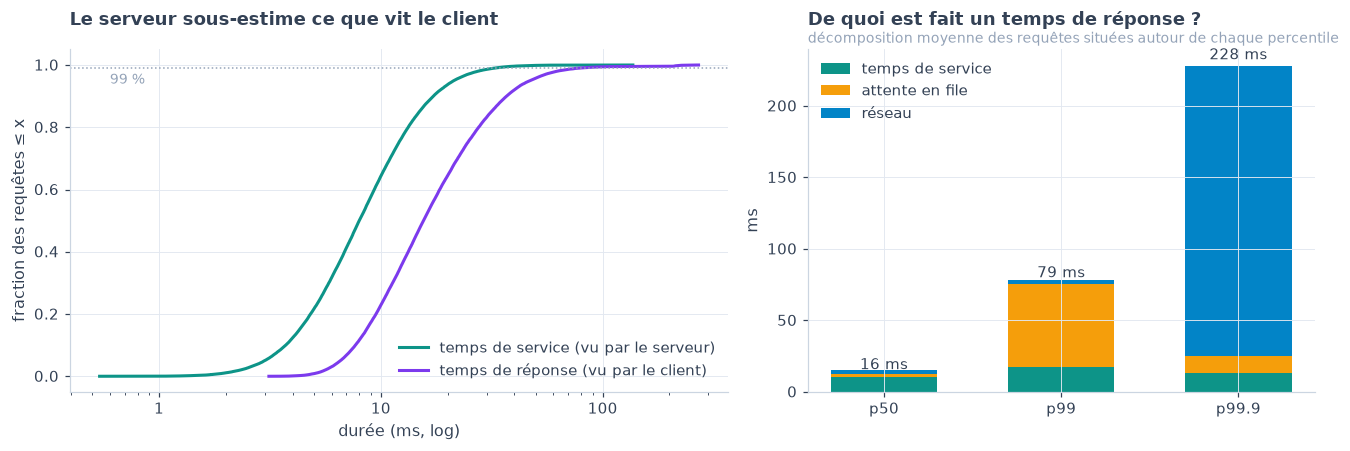

In [4]:
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw=dict(width_ratios=[1.3, 1]))
for col, color in zip(["temps de service (vu par le serveur)", "temps de réponse (vu par le client)"], [TEAL, VIOLET]):
    x = np.sort(D[col].values)
    ax.plot(x, np.arange(1, n + 1) / n, color=color, label=col)
ax.set_xscale("log"); rq.plain_log_axis(ax, "x")
ax.set_xlabel("durée (ms, log)"); ax.set_ylabel("fraction des requêtes ≤ x")
ax.axhline(0.99, color=GRAY, ls=":", lw=1); ax.text(0.6, 0.94, "99 %", color=GRAY, fontsize=9)
ax.set_title("Le serveur sous-estime ce que vit le client")
ax.legend(loc="lower right")

parts = ["temps de service (vu par le serveur)", "attente en file", "réseau (aller + retour)"]
qs = [50, 99, 99.9]
bottom = np.zeros(len(qs))
order = np.argsort(reponse)
for col, color in zip(parts, [TEAL, AMBER, SKY]):
    # contribution moyenne de chaque composante chez les requêtes situées autour du percentile
    vals = []
    for q in qs:
        k = int(q / 100 * n)
        idx = order[max(0, k - 50): k + 50]
        vals.append(D[col].values[idx].mean())
    ax2.bar([f"p{q:g}" for q in qs], vals, bottom=bottom, color=color, label=col.split(" (")[0], width=0.6)
    bottom += np.array(vals)
for i, b in enumerate(bottom):
    ax2.text(i, b * 1.02, f"{b:.0f} ms", ha="center", fontsize=9.5)
ax2.set_ylabel("ms"); ax2.set_title("De quoi est fait un temps de réponse ?")
subtitle(ax2, "décomposition moyenne des requêtes situées autour de chaque percentile")
ax2.legend(loc="upper left")
plt.tight_layout(); plt.show()

À la médiane, le temps de réponse est surtout fait de temps de service (le serveur n'est
occupé qu'à moitié, l'attente est souvent nulle). Mais plus on monte dans la queue, plus
il est dominé par **ce que le serveur ne voit pas** : au p99, l'attente en file (des
requêtes rapides bloquées derrière une lente, le **blocage en tête de file**,
head-of-line blocking) ; au p99,9, les retransmissions réseau. Un tableau de bord
alimenté par les seuls temps de service afficherait un p99 plus de deux fois trop
optimiste, et un p99,9 quatre fois trop optimiste.

> **À retenir.** Temps de réponse = latences réseau + attentes en file + temps de
> service. Les attentes et les aléas dominent la queue de la distribution et sont
> invisibles du serveur : on mesure côté client.

## 3. Une distribution, pas un nombre (section *Describing Performance*)

Même en répétant exactement la même requête, le temps de réponse varie : changement de
contexte vers un processus d'arrière-plan, paquet perdu, pause du ramasse-miettes (GC),
défaut de page... Il faut donc le penser comme une **distribution**. Traçons 100 requêtes
consécutives d'un service (générateur `rq.synthetic_response_times` : corps log-normal
plus 1,5 % de requêtes ralenties par un aléa).

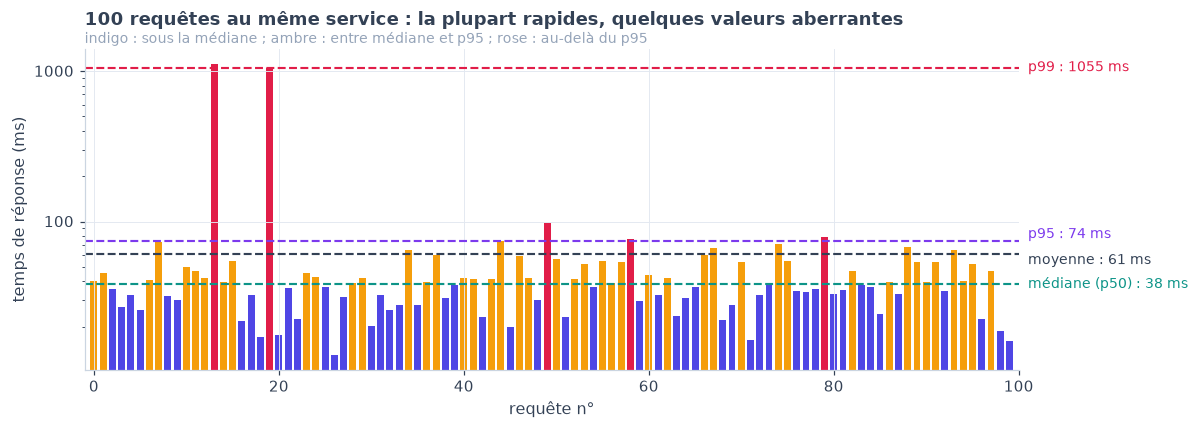

In [5]:
x100 = rq.synthetic_response_times(100, seed=7)
stats = {"moyenne": x100.mean(), "médiane (p50)": rq.percentile(x100, 50), "p95": rq.percentile(x100, 95),
         "p99": rq.percentile(x100, 99)}
fig, ax = plt.subplots(figsize=(11, 4))
cols = np.where(x100 > stats["p95"], ROSE, np.where(x100 > stats["médiane (p50)"], AMBER, INDIGO))
ax.bar(np.arange(100), x100, color=cols, width=0.75)
for (nom, v), c, va in zip(stats.items(), [SLATE, TEAL, VIOLET, ROSE], ["top", "center", "bottom", "center"]):
    ax.axhline(v, color=c, ls="--", lw=1.4)
    ax.text(101, v, f"{nom} : {v:.0f} ms", color=c, va=va, fontsize=9)
ax.set_xlim(-1, 100); ax.set_xlabel("requête n°"); ax.set_ylabel("temps de réponse (ms)")
ax.set_yscale("log"); rq.plain_log_axis(ax, "y")
ax.set_title("100 requêtes au même service : la plupart rapides, quelques valeurs aberrantes")
subtitle(ax, "indigo : sous la médiane ; ambre : entre médiane et p95 ; rose : au-delà du p95")
plt.tight_layout(); plt.show()

**La moyenne** (somme divisée par le nombre de requêtes) est utile pour estimer des
limites de débit, mais elle ne dit pas combien d'utilisateurs ont réellement subi tel
délai : ici, quelques requêtes lentes la tirent nettement au-dessus de la médiane, et
aucune requête ne prend « la moyenne ».

**Les percentiles** se lisent sur la liste triée. La **médiane** (p50) partage les
requêtes en deux moitiés : c'est le temps d'attente *typique*. Les percentiles élevés,
p95, p99, p999 (99,9e), mesurent la gravité des valeurs aberrantes : un p95 de 1,5 s
signifie que 5 requêtes sur 100 prennent 1,5 s ou plus. On les appelle **latences de
queue** (tail latencies).

Sur 100 000 requêtes, la forme de la distribution apparaît nettement : un corps
en cloche (en échelle log) et une **seconde bosse** de requêtes ralenties.

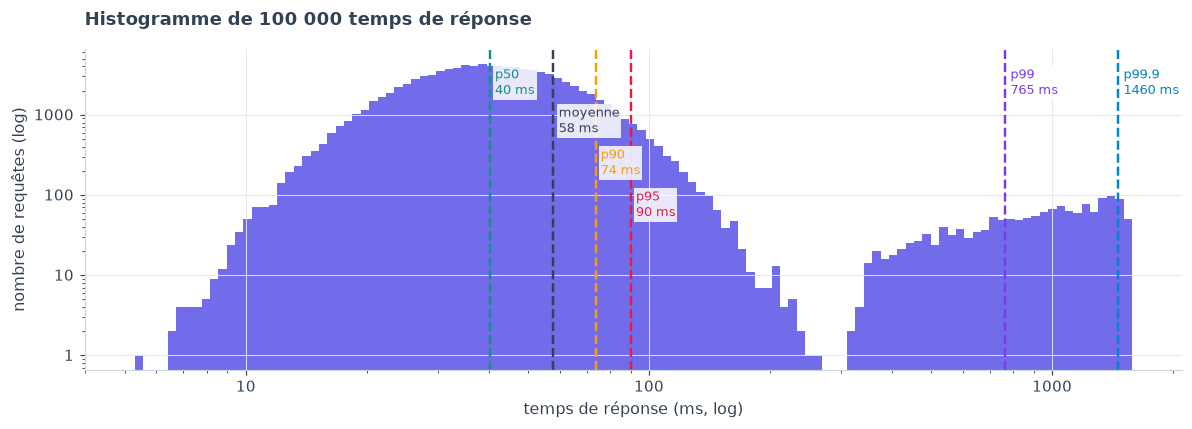

,moyenne,p50,p90,p95,p99,p99.9
valeur (ms),58.0,40.3,73.7,90.1,764.9,1459.6


In [6]:
x = rq.synthetic_response_times(100_000, seed=0)
fig, ax = plt.subplots(figsize=(11, 4))
bins = np.logspace(np.log10(x.min()), np.log10(x.max()), 120)
ax.hist(x, bins=bins, color=INDIGO, alpha=0.8)
ax.set_xscale("log"); ax.set_yscale("log"); rq.plain_log_axis(ax)
ymax = ax.get_ylim()[1]
hauteurs = [0.2, 0.6, 0.06, 0.018, 0.6, 0.6]
for (nom, v), c, hy in zip([("moyenne", x.mean())] + [(f"p{q:g}", rq.percentile(x, q)) for q in Q],
                           [SLATE] + COLORS[1:], hauteurs):
    ax.axvline(v, color=c, lw=1.6, ls="--")
    ax.text(v * 1.03, ymax * hy, f"{nom}\n{v:.0f} ms", color=c, fontsize=8.5, va="top",
            bbox=dict(fc="white", ec="none", alpha=0.85, pad=1))
ax.set_xlabel("temps de réponse (ms, log)"); ax.set_ylabel("nombre de requêtes (log)")
ax.set_title("Histogramme de 100 000 temps de réponse")
plt.tight_layout(); plt.show()
pd.DataFrame({"valeur (ms)": [x.mean()] + [rq.percentile(x, q) for q in Q]},
             index=["moyenne"] + [f"p{q:g}" for q in Q]).T

Le p99 tombe dans la bosse des requêtes ralenties : il vaut une vingtaine de fois la
médiane. La moyenne, elle, se situe entre la médiane et le p95, sans signification
particulière.

**Pourquoi s'intéresser au p999 ?** Le livre cite Amazon, qui fixe ses exigences internes
au 99,9e percentile alors que cela ne concerne qu'une requête sur 1 000 : les clients
dont les requêtes sont les plus lentes sont souvent ceux qui ont le plus de données
(beaucoup d'achats), donc les plus précieux. Aller plus loin (p9999) a été jugé trop
coûteux pour un bénéfice trop faible : les très hauts percentiles dépendent d'aléas qu'on
ne maîtrise pas.

Il y a une autre raison, plus mathématique : un utilisateur fait **beaucoup de
requêtes**. Une session de chargement de page qui déclenche 30 requêtes en voit au moins
une au-delà du p99 avec une probabilité $1 - 0{,}99^{30} \approx 26\,\%$. Les queues de
distribution concernent donc bien plus d'utilisateurs que leur nom ne le laisse croire.

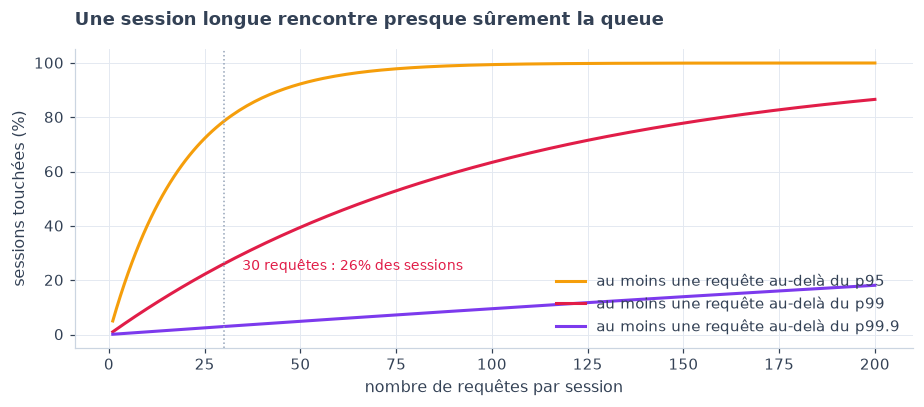

In [7]:
k = np.arange(1, 201)
fig, ax = plt.subplots(figsize=(8.5, 3.8))
for q, c in [(95, AMBER), (99, ROSE), (99.9, VIOLET)]:
    ax.plot(k, rq.p_any_slow(1 - q / 100, k) * 100, color=c, label=f"au moins une requête au-delà du p{q:g}")
ax.axvline(30, color=GRAY, ls=":", lw=1)
ax.annotate(f"30 requêtes : {rq.p_any_slow(0.01, 30):.0%} des sessions", (30, rq.p_any_slow(0.01, 30) * 100), (12, -4),
            textcoords="offset points", fontsize=9, color=ROSE)
ax.set_xlabel("nombre de requêtes par session"); ax.set_ylabel("sessions touchées (%)")
ax.set_title("Une session longue rencontre presque sûrement la queue")
ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

> **À retenir.** Le temps de réponse est une distribution. La médiane décrit le cas
> typique, les hauts percentiles (p99, p999) les cas lents ; la moyenne ne décrit
> personne. Comme un utilisateur fait de nombreuses requêtes, la queue le concerne
> presque toujours.